# 🍽️ Zomato Restaurants: Exploratory Data Analysis

**Goal:** understand what drives restaurant ratings, popularity and pricing on Zomato, and produce a clean, analysis-ready dataset.

**Stack:** `pandas` · `numpy` · `matplotlib` (no other plotting libraries)

**Dataset:** 9,551 restaurants from 15 countries, 21 columns (restaurant info, location, cuisines, cost, ratings, votes, service options).

### Contents
1. Load & first look
2. Data cleaning
3. Outlier check
4. Univariate analysis
5. Bivariate & multivariate analysis
6. Key insights
7. Save the cleaned dataset

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

RED, DARK, GREY = "#E23744", "#1C1C1C", "#BDBDBD"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titleweight": "bold",
    "figure.dpi": 100,
})

os.makedirs("images", exist_ok=True)
os.makedirs("data", exist_ok=True)


def save_fig(name):
    """Save the current figure to images/ and display it."""
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Load & first look

In [2]:
RAW_PATH = "data/Zomato_Restaurant_Dataset.csv"
df_raw = pd.read_csv(RAW_PATH)
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   str    
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   str    
 4   Address               9551 non-null   str    
 5   Locality              9551 non-null   str    
 6   Locality Verbose      9551 non-null   str    
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   str    
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   str    
 12  Has Table booking     9551 non-null   str    
 13  Has Online delivery   9551 non-null   str    
 14  Is delivering now     9551 non-null   str    
 15  Switch to order menu  9551 non-n

In [4]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Restaurant ID,9551.0,9.051128e+06,8.791521e+06,53.000000,301962.500000,6.004089e+06,1.835229e+07,1.850065e+07
Country Code,9551.0,1.836562e+01,5.675055e+01,1.000000,1.000000,1.000000e+00,1.000000e+00,2.160000e+02
Longitude,9551.0,6.412657e+01,4.146706e+01,-157.948486,77.081343,7.719196e+01,7.728201e+01,1.748321e+02
Latitude,9551.0,2.585438e+01,1.100794e+01,-41.330428,28.478713,2.857047e+01,2.864276e+01,5.597698e+01
Average Cost for two,9551.0,1.199211e+03,1.612118e+04,0.000000,250.000000,4.000000e+02,7.000000e+02,8.000000e+05
Price range,9551.0,1.804837e+00,9.056088e-01,1.000000,1.000000,2.000000e+00,2.000000e+00,4.000000e+00
Aggregate rating,9551.0,2.666370e+00,1.516378e+00,0.000000,2.500000,3.200000e+00,3.700000e+00,4.900000e+00
Votes,9551.0,1.569097e+02,4.301691e+02,0.000000,5.000000,3.100000e+01,1.310000e+02,1.093400e+04


### 1.1 Quick data-quality audit
Standard checks first (nulls, duplicates), then a look for *hidden* problems that `isna()` does not catch.

In [5]:
quality = pd.DataFrame({
    "missing": df_raw.isna().sum(),
    "missing_%": (df_raw.isna().mean() * 100).round(2),
    "n_unique": df_raw.nunique(),
})
print("Duplicate rows          :", df_raw.duplicated().sum())
print("Duplicate Restaurant IDs:", df_raw["Restaurant ID"].duplicated().sum())
quality

Duplicate rows          : 0
Duplicate Restaurant IDs: 0


,missing,missing_%,n_unique
Restaurant ID,0,0.00,9551
Restaurant Name,0,0.00,7446
Country Code,0,0.00,15
City,0,0.00,141
Address,0,0.00,8918
Locality,0,0.00,1208
Locality Verbose,0,0.00,1265
Longitude,0,0.00,8120
Latitude,0,0.00,8677
Cuisines,9,0.09,1825


In [6]:
# Hidden problem #1: the "Currency" column vs. the real country of each code
chk = df_raw.groupby("Country Code").agg(
    currency=("Currency", "first"),
    sample_city=("City", "first"),
    restaurants=("City", "size"),
)
chk

,currency,sample_city,restaurants
Country Code,,,
1,Indian Rupees(Rs.),Agra,8652
14,Dollar($),Armidale,24
30,Brazilian Real(R$),Bras�_lia,60
37,Dollar($),Chatham-Kent,4
94,Indonesian Rupiah(IDR),Bandung,21
148,NewZealand($),Auckland,40
162,Botswana Pula(P),Makati City,22
166,Qatari Rial(QR),Doha,20
184,Dollar($),Singapore,20


In [7]:
# Hidden problem #2: placeholder zeros, constant columns, corrupted text
print("Constant columns:", [c for c in df_raw.columns if df_raw[c].nunique() == 1])
print("Rating text for rating == 0:", df_raw.loc[df_raw["Aggregate rating"] == 0, "Rating text"].unique())
print("Corrupted City values:", sorted(df_raw.loc[df_raw["City"].str.contains("\ufffd"), "City"].unique()))
print("Corrupted currency   :", df_raw.loc[df_raw["Currency"].str.contains("\ufffd"), "Currency"].unique())

Constant columns: ['Switch to order menu']
Rating text for rating == 0: <StringArray>
['Not rated']
Length: 1, dtype: str
Corrupted City values: ['Bras�_lia', 'S��o Paulo', '��stanbul']
Corrupted currency   : <StringArray>
['Pounds(��)']
Length: 1, dtype: str


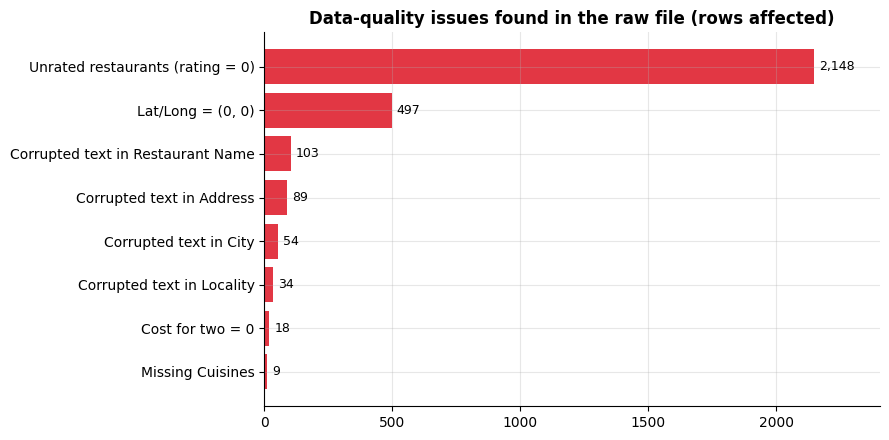

In [8]:
issue_counts = pd.Series({
    "Unrated restaurants (rating = 0)": (df_raw["Aggregate rating"] == 0).sum(),
    "Lat/Long = (0, 0)": ((df_raw["Longitude"] == 0) & (df_raw["Latitude"] == 0)).sum(),
    "Corrupted text in Restaurant Name": df_raw["Restaurant Name"].str.contains("\ufffd").sum(),
    "Corrupted text in Address": df_raw["Address"].str.contains("\ufffd").sum(),
    "Corrupted text in Locality": df_raw["Locality"].str.contains("\ufffd").sum(),
    "Cost for two = 0": (df_raw["Average Cost for two"] == 0).sum(),
    "Missing Cuisines": df_raw["Cuisines"].isna().sum(),
    "Corrupted text in City": df_raw["City"].str.contains("\ufffd").sum(),
}).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(issue_counts.index, issue_counts.values, color=RED)
for i, v in enumerate(issue_counts.values):
    ax.text(v + 20, i, f"{v:,}", va="center", fontsize=9)
ax.set_title("Data-quality issues found in the raw file (rows affected)")
ax.set_xlim(0, issue_counts.max() * 1.12)
save_fig("01_data_quality_issues")

**What the audit tells us**

| Issue | Why it matters | Fix |
|---|---|---|
| Only 9 nulls (`Cuisines`) | Looks clean, but... | Fill with `"Not Specified"` |
| 2,148 ratings of `0.0` | These are **"Not rated"**, not terrible restaurants. Keeping them would drag every average down | Set to `NaN` and add an `Is Rated` flag |
| 497 coordinates at (0, 0) | Placeholder, not a real location | Set to `NaN` |
| 18 costs of `0` | Placeholder for missing | Set to `NaN` |
| `Currency` differs per country | Costs cannot be compared across countries as-is | Standardise to ISO codes, add an approximate USD column |
| Country `162` labelled *Botswana Pula* | Its cities (Makati, Pasig, Quezon City…) are in the **Philippines** | Correct to `PHP` |
| No country *names* | Only numeric codes | Map codes to names |
| Corrupted characters (`�`) | Source file lost accents (`S��o Paulo`) | Repair cities and the currency symbol; names/addresses can't be recovered reliably, so they're left as-is |
| `Switch to order menu` is always `No` | Zero information | Drop |

## 2. Data cleaning
All steps are applied to a copy (`df`), so the raw data stays untouched in `df_raw`.

In [9]:
df = df_raw.copy()

# 2.1 Trim stray whitespace in text columns
text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for c in text_cols:
    df[c] = df[c].str.strip()

# 2.2 Country names (Zomato's country-code table) and ISO currency codes
country_map = {
    1: "India", 14: "Australia", 30: "Brazil", 37: "Canada", 94: "Indonesia",
    148: "New Zealand", 162: "Philippines", 166: "Qatar", 184: "Singapore",
    189: "South Africa", 191: "Sri Lanka", 208: "Turkey", 214: "UAE",
    215: "United Kingdom", 216: "United States",
}
currency_map = {
    1: "INR", 14: "AUD", 30: "BRL", 37: "CAD", 94: "IDR", 148: "NZD",
    162: "PHP", 166: "QAR", 184: "SGD", 189: "ZAR", 191: "LKR",
    208: "TRY", 214: "AED", 215: "GBP", 216: "USD",
}
df["Country"] = df["Country Code"].map(country_map)
df["Currency Code"] = df["Country Code"].map(currency_map)
df = df.drop(columns=["Currency"])

# 2.3 Repair corrupted city names
city_fix = {
    "Bras\ufffd_lia": "Brasília",
    "S\ufffd\ufffdo Paulo": "São Paulo",
    "\ufffd\ufffdstanbul": "Istanbul",
}
df["City"] = df["City"].replace(city_fix)

# 2.4 Missing cuisines
df["Cuisines"] = df["Cuisines"].fillna("Not Specified")

# 2.5 Placeholder zeros -> real missing values
df["Is Rated"] = df["Aggregate rating"] > 0
df.loc[~df["Is Rated"], "Aggregate rating"] = np.nan

df["Average Cost for two"] = df["Average Cost for two"].astype(float)
df.loc[df["Average Cost for two"] == 0, "Average Cost for two"] = np.nan

no_geo = (df["Longitude"] == 0) & (df["Latitude"] == 0)
df.loc[no_geo, ["Longitude", "Latitude"]] = np.nan

# 2.6 Drop the constant column
df = df.drop(columns=["Switch to order menu"])

print("Corrupted cities left:", df["City"].str.contains("\ufffd").sum())
print("Unknown countries    :", df["Country"].isna().sum())

Corrupted cities left: 0
Unknown countries    : 0


In [10]:
# 2.7 Approximate USD cost so countries can be compared.
# NOTE: fixed, rounded exchange rates (circa the period the data was collected) -
# good enough for comparing price *levels*, not for exact conversions.
usd_per_unit = {
    "INR": 0.0147, "AUD": 0.75, "BRL": 0.27, "CAD": 0.77, "IDR": 0.000071,
    "NZD": 0.68, "PHP": 0.019, "QAR": 0.275, "SGD": 0.74, "ZAR": 0.074,
    "LKR": 0.0063, "TRY": 0.22, "AED": 0.272, "GBP": 1.33, "USD": 1.0,
}
df["Cost for two (USD)"] = (df["Average Cost for two"] * df["Currency Code"].map(usd_per_unit)).round(2)

# 2.8 Simple feature engineering from the Cuisines column
df["Num Cuisines"] = df["Cuisines"].where(df["Cuisines"] != "Not Specified").str.split(", ").str.len()
df["Primary Cuisine"] = df["Cuisines"].str.split(", ").str[0]

df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Has Table booking,Has Online delivery,Is delivering now,Price range,Aggregate rating,Rating color,Rating text,Votes,Country,Currency Code,Is Rated,Cost for two (USD),Num Cuisines,Primary Cuisine
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",1100.0,Yes,No,No,3,4.8,Dark Green,Excellent,314,Philippines,PHP,True,20.9,3.0,French
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,1200.0,Yes,No,No,3,4.5,Dark Green,Excellent,591,Philippines,PHP,True,22.8,1.0,Japanese
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000.0,Yes,No,No,4,4.4,Green,Very Good,270,Philippines,PHP,True,76.0,4.0,Seafood
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",1500.0,No,No,No,4,4.9,Dark Green,Excellent,365,Philippines,PHP,True,28.5,2.0,Japanese
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",1500.0,Yes,No,No,4,4.8,Dark Green,Excellent,229,Philippines,PHP,True,28.5,2.0,Japanese


In [11]:
# 2.9 Validate the result
print("Shape before:", df_raw.shape, "-> after:", df.shape, "\n")
after = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()})
after[after["missing"] > 0]

Shape before: (9551, 21) -> after: (9551, 25) 



,dtype,missing
Longitude,float64,497
Latitude,float64,497
Average Cost for two,float64,18
Aggregate rating,float64,2148
Cost for two (USD),float64,18
Num Cuisines,float64,9


The remaining missing values are **intentional**: they are placeholders that were turned into real `NaN`s, so statistics are no longer polluted by fake zeros.

## 3. Outlier check
Using the IQR rule (values beyond 1.5 × IQR from the quartiles). Before deciding whether to remove anything, check whether the extremes are *errors* or *real*.

In [12]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((s < lo) | (s > hi)).sum()), lo, hi

rows = []
for col in ["Votes", "Cost for two (USD)", "Aggregate rating", "Num Cuisines"]:
    s = df[col].dropna()
    n, lo, hi = iqr_outliers(s)
    rows.append({"column": col, "outliers": n, "outlier_%": round(n / len(s) * 100, 2),
                 "lower_fence": round(lo, 2), "upper_fence": round(hi, 2), "max": s.max()})
pd.DataFrame(rows)

,column,outliers,outlier_%,lower_fence,upper_fence,max
0,Votes,1126,11.79,-184.00,320.00,10934.0
1,Cost for two (USD),1125,11.80,-6.61,22.78,370.0
2,Aggregate rating,1,0.01,1.80,5.00,4.9
3,Num Cuisines,42,0.44,-2.00,6.00,8.0


In [13]:
print("Top 5 most-voted restaurants")
print(df.nlargest(5, "Votes")[["Restaurant Name", "City", "Votes", "Aggregate rating"]].to_string(index=False))
print("\nTop 5 most expensive (approx. USD for two)")
print(df.nlargest(5, "Cost for two (USD)")[["Restaurant Name", "City", "Average Cost for two", "Currency Code", "Cost for two (USD)"]].to_string(index=False))

Top 5 most-voted restaurants
          Restaurant Name      City  Votes  Aggregate rating
                     Toit Bangalore  10934               4.8
                 Truffles Bangalore   9667               4.7
         Hauz Khas Social New Delhi   7931               4.3
                Peter Cat   Kolkata   7574               4.3
AB's - Absolute Barbecues Bangalore   6907               4.6

Top 5 most expensive (approx. USD for two)
               Restaurant Name      City  Average Cost for two Currency Code  Cost for two (USD)
              Restaurant Andre Singapore                 500.0           SGD              370.00
                          Jaan Singapore                 430.0           SGD              318.20
      Restaurant Gordon Ramsay    London                 230.0           GBP              305.90
Restaurant Mosaic @ The Orient  Pretoria                3210.0           ZAR              237.54
         Rhubarb Le Restaurant Singapore                 315.0           SGD

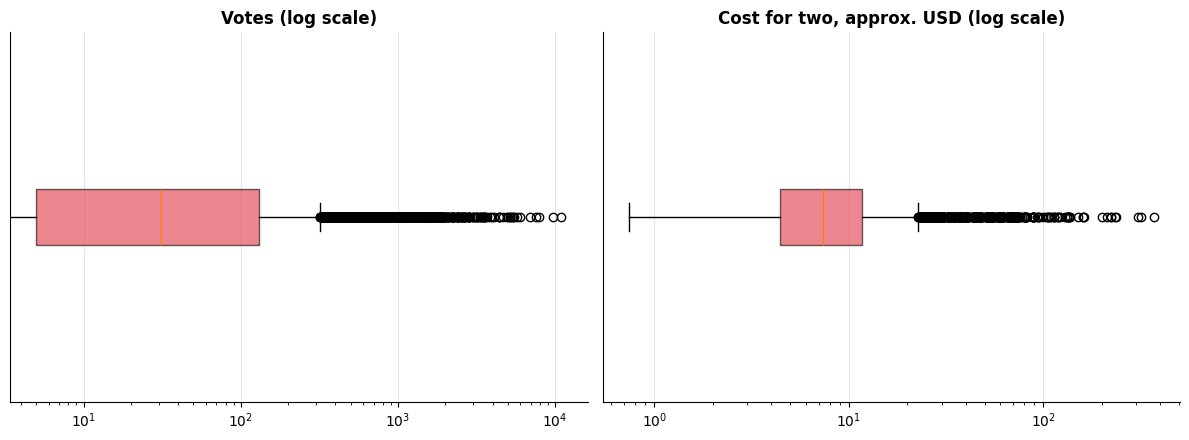

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].boxplot(df["Votes"], vert=False, patch_artist=True, boxprops=dict(facecolor=RED, alpha=0.6))
ax[0].set_xscale("log")
ax[0].set_yticks([])
ax[0].set_title("Votes (log scale)")

ax[1].boxplot(df["Cost for two (USD)"].dropna(), vert=False, patch_artist=True, boxprops=dict(facecolor=RED, alpha=0.6))
ax[1].set_xscale("log")
ax[1].set_yticks([])
ax[1].set_title("Cost for two, approx. USD (log scale)")
save_fig("02_outliers_boxplots")

**Decision: keep the outliers.**
- **Votes:** 11.8% of restaurants sit above 320 votes. These are genuinely popular venues (e.g. Toit, Bangalore, 10,934 votes), which is real signal, not error.
- **Cost:** pooled across currencies, the IQR rule flags 11.8% of restaurants, but 52% of those are non-Indian places that look "expensive" only because India is cheap in USD terms. Inside India alone (INR), 9.4% of restaurants are above ₹1,300, up to ₹8,000, which is real fine dining.
- The scary raw maximum (800,000) is *Skye, Jakarta* priced in **Indonesian Rupiah** (≈ $57), a currency artefact that the USD column resolves.

For visualisation we use log scales or cap at the 99th percentile instead of deleting data.

## 4. Univariate analysis

India share of all restaurants: 90.6%
Delhi NCR (New Delhi, Gurgaon, Noida, Faridabad, Ghaziabad): 83.2%


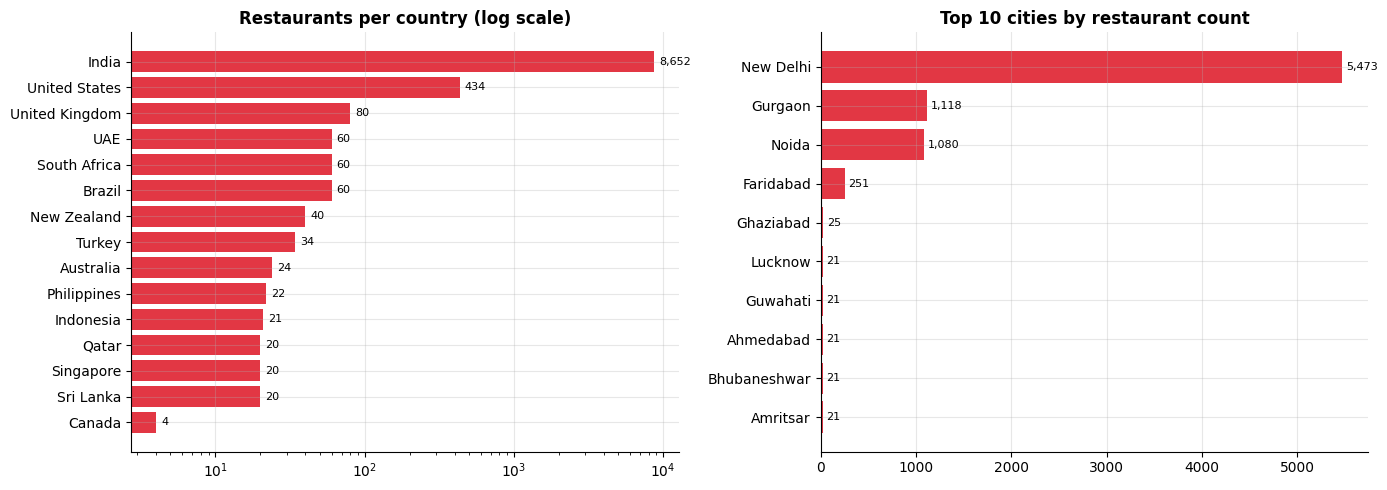

In [15]:
rated = df[df["Is Rated"]]
india = df[df["Country"] == "India"]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

country_counts = df["Country"].value_counts().sort_values()
ax[0].barh(country_counts.index, country_counts.values, color=RED)
ax[0].set_xscale("log")
for i, v in enumerate(country_counts.values):
    ax[0].text(v * 1.08, i, f"{v:,}", va="center", fontsize=8)
ax[0].set_title("Restaurants per country (log scale)")

city_counts = df["City"].value_counts().head(10).sort_values()
ax[1].barh(city_counts.index, city_counts.values, color=RED)
for i, v in enumerate(city_counts.values):
    ax[1].text(v + 40, i, f"{v:,}", va="center", fontsize=8)
ax[1].set_title("Top 10 cities by restaurant count")
save_fig("03_restaurants_by_country_city")

print(f"India share of all restaurants: {len(india) / len(df):.1%}")
print(f"Delhi NCR (New Delhi, Gurgaon, Noida, Faridabad, Ghaziabad): "
      f"{df['City'].isin(['New Delhi', 'Gurgaon', 'Noida', 'Faridabad', 'Ghaziabad']).mean():.1%}")

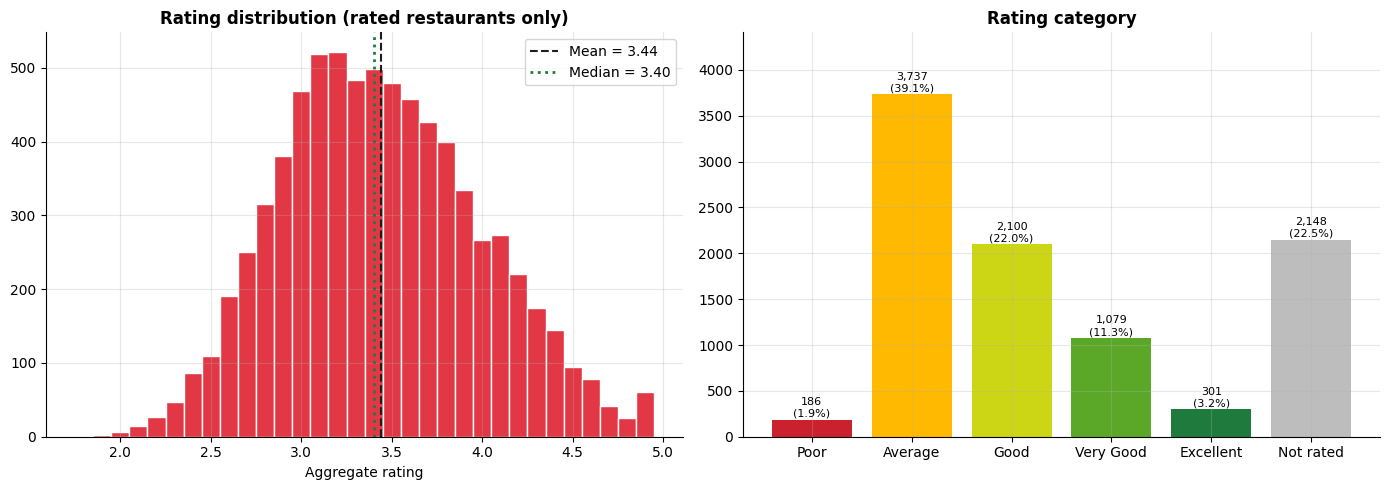

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].hist(rated["Aggregate rating"], bins=np.arange(1.75, 5.0, 0.1), color=RED, edgecolor="white")
mean_r, med_r = rated["Aggregate rating"].mean(), rated["Aggregate rating"].median()
ax[0].axvline(mean_r, color=DARK, ls="--", label=f"Mean = {mean_r:.2f}")
ax[0].axvline(med_r, color="#1F7A3E", ls=":", lw=2, label=f"Median = {med_r:.2f}")
ax[0].set_xlabel("Aggregate rating")
ax[0].set_title("Rating distribution (rated restaurants only)")
ax[0].legend()

order = ["Poor", "Average", "Good", "Very Good", "Excellent", "Not rated"]
colors = ["#CB202D", "#FFBA00", "#CDD614", "#5BA829", "#1F7A3E", GREY]
counts = df["Rating text"].value_counts().reindex(order)
ax[1].bar(order, counts.values, color=colors)
for i, v in enumerate(counts.values):
    ax[1].text(i, v + 30, f"{v:,}\n({v / len(df):.1%})", ha="center", fontsize=8)
ax[1].set_ylim(0, counts.max() * 1.18)
ax[1].set_title("Rating category")
save_fig("04_rating_distribution")

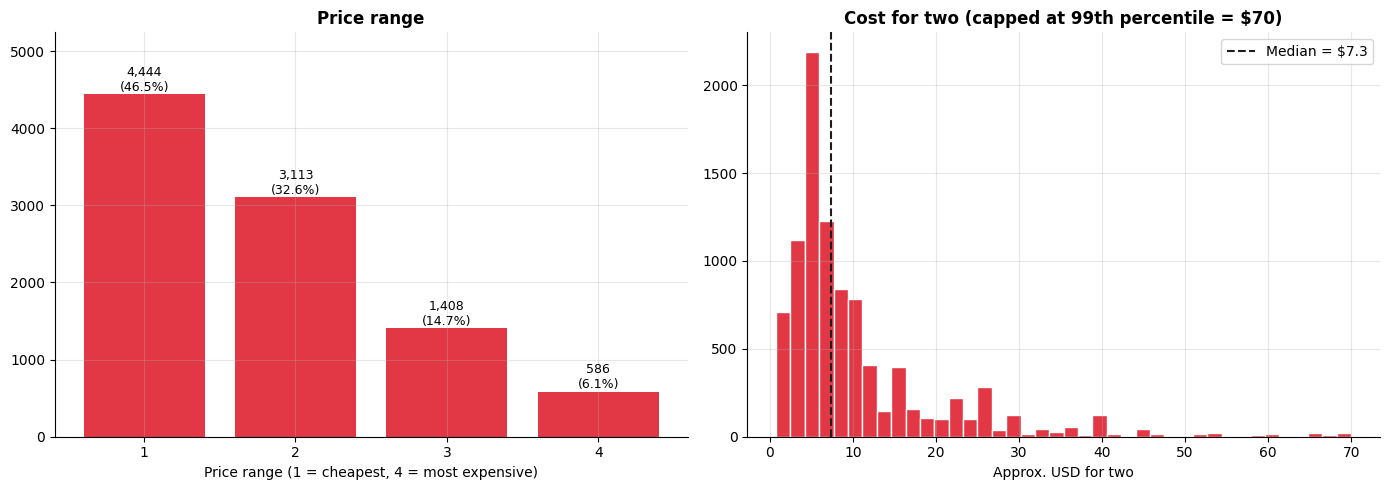

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

pr = df["Price range"].value_counts().sort_index()
ax[0].bar(pr.index.astype(str), pr.values, color=RED)
for i, v in enumerate(pr.values):
    ax[0].text(i, v + 40, f"{v:,}\n({v / len(df):.1%})", ha="center", fontsize=9)
ax[0].set_ylim(0, pr.max() * 1.18)
ax[0].set_xlabel("Price range (1 = cheapest, 4 = most expensive)")
ax[0].set_title("Price range")

cost = df["Cost for two (USD)"].dropna()
cap = cost.quantile(0.99)
ax[1].hist(cost[cost <= cap], bins=40, color=RED, edgecolor="white")
ax[1].axvline(cost.median(), color=DARK, ls="--", label=f"Median = ${cost.median():.1f}")
ax[1].set_xlabel("Approx. USD for two")
ax[1].set_title(f"Cost for two (capped at 99th percentile = ${cap:.0f})")
ax[1].legend()
save_fig("05_price_range_and_cost")

count     9551.0
mean       156.9
std        430.2
min          0.0
25%          5.0
50%         31.0
75%        131.0
max      10934.0

Restaurants with 10 or fewer votes: 33.7%


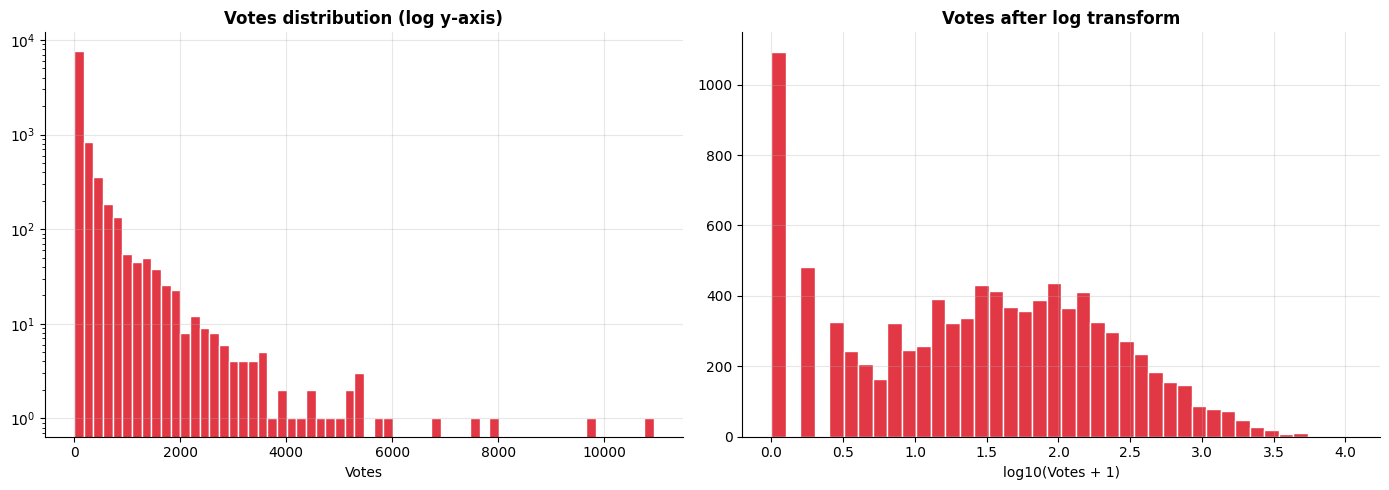

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].hist(df["Votes"], bins=60, color=RED, edgecolor="white")
ax[0].set_yscale("log")
ax[0].set_xlabel("Votes")
ax[0].set_title("Votes distribution (log y-axis)")

ax[1].hist(np.log10(df["Votes"] + 1), bins=40, color=RED, edgecolor="white")
ax[1].set_xlabel("log10(Votes + 1)")
ax[1].set_title("Votes after log transform")
save_fig("06_votes_distribution")

print(df["Votes"].describe().round(1).to_string())
print(f"\nRestaurants with 10 or fewer votes: {(df['Votes'] <= 10).mean():.1%}")

Unique cuisines: 145
Average cuisines listed per restaurant: 2.07


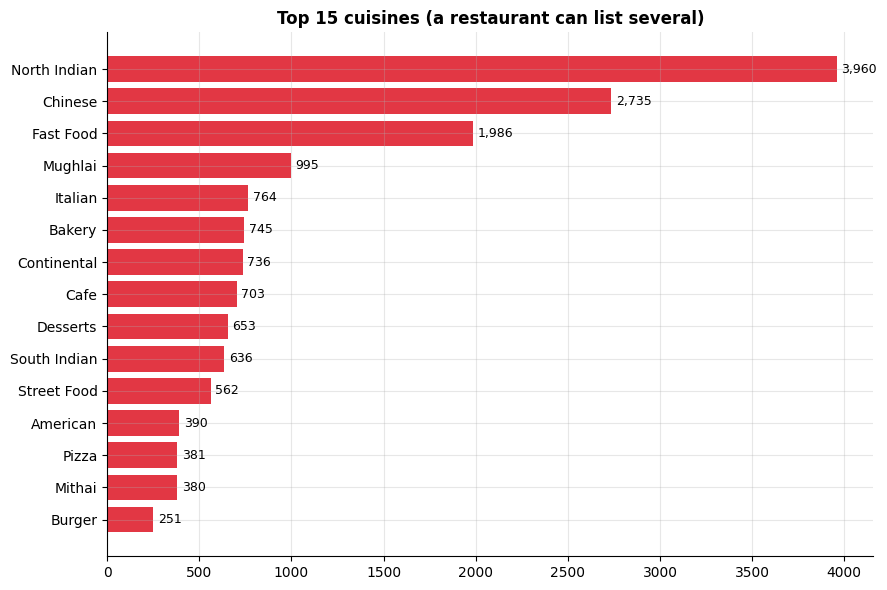

In [19]:
cuisine_df = df.assign(Cuisine=df["Cuisines"].str.split(", ")).explode("Cuisine")
cuisine_df = cuisine_df[cuisine_df["Cuisine"] != "Not Specified"]
cuisine_counts = cuisine_df["Cuisine"].value_counts()

top = cuisine_counts.head(15).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color=RED)
for i, v in enumerate(top.values):
    ax.text(v + 25, i, f"{v:,}", va="center", fontsize=9)
ax.set_title("Top 15 cuisines (a restaurant can list several)")
save_fig("07_top_cuisines")

print("Unique cuisines:", cuisine_counts.size)
print(f"Average cuisines listed per restaurant: {df['Num Cuisines'].mean():.2f}")

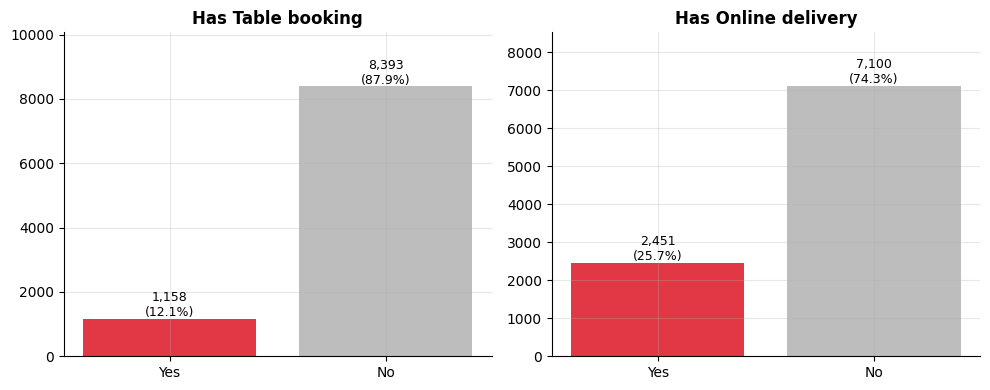

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, col in zip(ax, ["Has Table booking", "Has Online delivery"]):
    vc = df[col].value_counts().reindex(["Yes", "No"])
    a.bar(vc.index, vc.values, color=[RED, GREY])
    for i, v in enumerate(vc.values):
        a.text(i, v + 80, f"{v:,}\n({v / len(df):.1%})", ha="center", fontsize=9)
    a.set_ylim(0, vc.max() * 1.2)
    a.set_title(col)
save_fig("08_service_features")

## 5. Bivariate & multivariate analysis

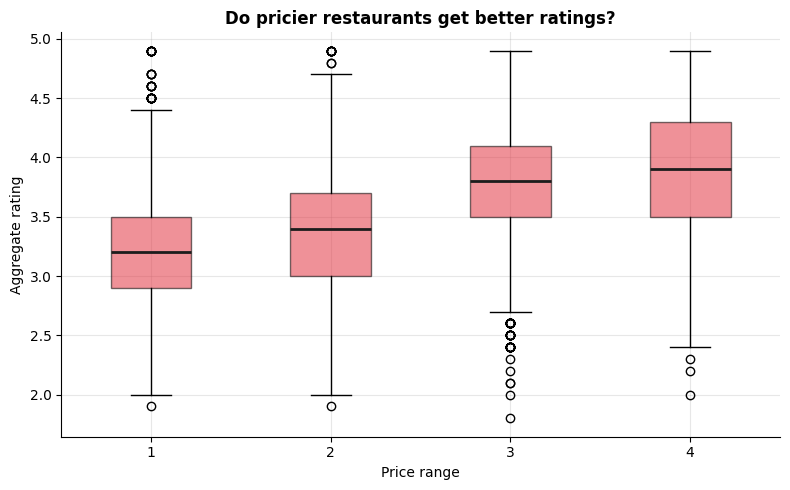

,count,mean,median
Price range,,,
1,2744,3.24,3.2
2,2711,3.38,3.4
3,1373,3.78,3.8
4,575,3.89,3.9


In [21]:
groups = [rated.loc[rated["Price range"] == p, "Aggregate rating"] for p in [1, 2, 3, 4]]
fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot(groups, patch_artist=True, medianprops=dict(color=DARK, lw=2))
for box in bp["boxes"]:
    box.set(facecolor=RED, alpha=0.55)
ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels(["1", "2", "3", "4"])
ax.set_xlabel("Price range")
ax.set_ylabel("Aggregate rating")
ax.set_title("Do pricier restaurants get better ratings?")
save_fig("09_rating_by_price_range")

rated.groupby("Price range")["Aggregate rating"].agg(["count", "mean", "median"]).round(2)

Spearman correlation (rating, votes): 0.68

Median votes per rating band:
Aggregate rating
Poor          61.0
Average       20.0
Good         121.0
Very Good    271.0
Excellent    489.0


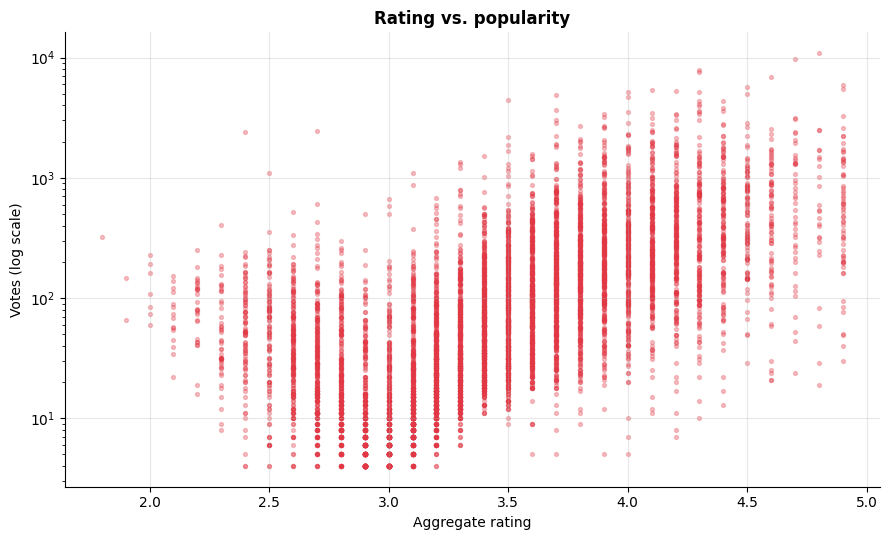

In [22]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(rated["Aggregate rating"], rated["Votes"], s=8, alpha=0.3, color=RED)
ax.set_yscale("log")
ax.set_xlabel("Aggregate rating")
ax.set_ylabel("Votes (log scale)")
ax.set_title("Rating vs. popularity")
save_fig("10_votes_vs_rating")

rho = rated[["Aggregate rating", "Votes"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman correlation (rating, votes): {rho:.2f}")
print("\nMedian votes per rating band:")
bands = pd.cut(rated["Aggregate rating"], [0, 2.4, 3.4, 3.9, 4.4, 5], labels=["Poor", "Average", "Good", "Very Good", "Excellent"])
print(rated.groupby(bands, observed=True)["Votes"].median().to_string())

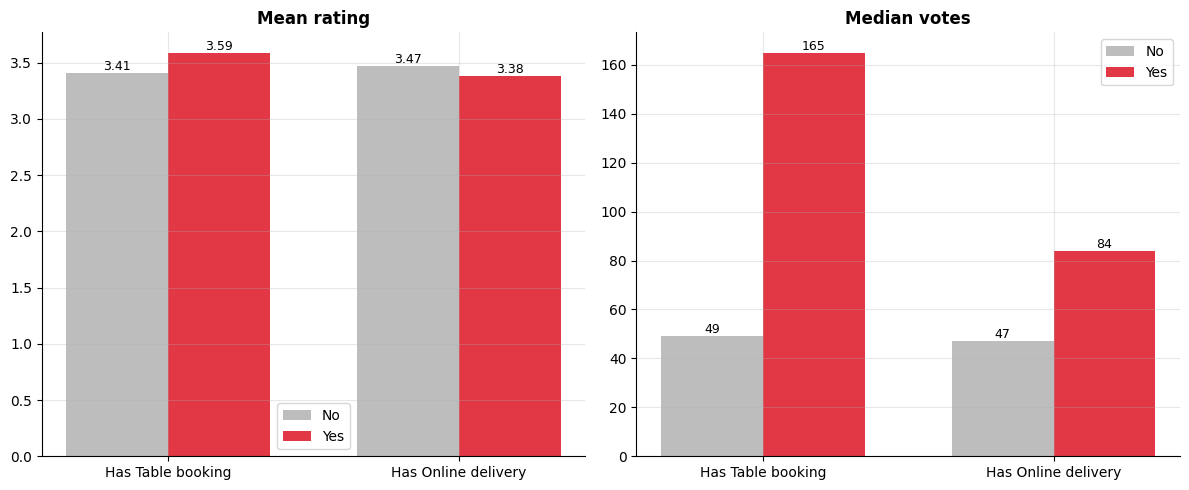

,feature,value,restaurants,mean_rating,median_votes,mean_price_range
0,Has Table booking,No,6292,3.41,49.0,1.78
1,Has Table booking,Yes,1111,3.59,165.0,3.04
2,Has Online delivery,No,5048,3.47,47.0,1.98
3,Has Online delivery,Yes,2355,3.38,84.0,1.94


In [23]:
rows = []
for col in ["Has Table booking", "Has Online delivery"]:
    for val in ["No", "Yes"]:
        s = rated[rated[col] == val]
        rows.append({"feature": col, "value": val, "restaurants": len(s),
                     "mean_rating": s["Aggregate rating"].mean(),
                     "median_votes": s["Votes"].median(),
                     "mean_price_range": s["Price range"].mean()})
svc = pd.DataFrame(rows).round(2)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
x, w = np.arange(2), 0.35
features = ["Has Table booking", "Has Online delivery"]
for a, metric, title in zip(ax, ["mean_rating", "median_votes"], ["Mean rating", "Median votes"]):
    no = svc[svc["value"] == "No"][metric].values
    yes = svc[svc["value"] == "Yes"][metric].values
    b1 = a.bar(x - w / 2, no, w, label="No", color=GREY)
    b2 = a.bar(x + w / 2, yes, w, label="Yes", color=RED)
    for bars in (b1, b2):
        for r in bars:
            a.text(r.get_x() + r.get_width() / 2, r.get_height(), f"{r.get_height():g}", ha="center", va="bottom", fontsize=9)
    a.set_xticks(x)
    a.set_xticklabels(features)
    a.set_title(title)
    a.legend()
save_fig("11_service_features_effect")

svc

**Careful: this is confounded.** Restaurants with table booking have a much higher average price range (see the last column), and price range itself is linked to rating. So is it the *booking* or the *price*? Compare like with like by holding price range fixed (India only, one rating culture; price range 1 is skipped because only one such restaurant offers booking).

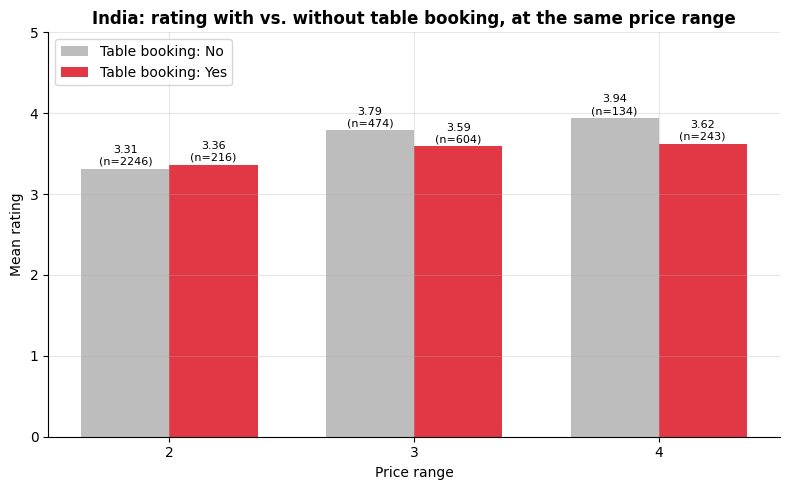

count  mean
Price range Has Table booking             
2           No                  2246  3.31
            Yes                  216  3.36
3           No                   474  3.79
            Yes                  604  3.59
4           No                   134  3.94
            Yes                  243  3.62

In [24]:
r_in = india[india["Is Rated"] & india["Price range"].isin([2, 3, 4])]
ctrl = (r_in.groupby(["Price range", "Has Table booking"])["Aggregate rating"]
            .agg(["count", "mean"]).round(2))

fig, ax = plt.subplots(figsize=(8, 5))
x, w = np.arange(3), 0.36
for k, (val, color) in enumerate([("No", GREY), ("Yes", RED)]):
    means = [ctrl.loc[(p, val), "mean"] for p in [2, 3, 4]]
    ns = [ctrl.loc[(p, val), "count"] for p in [2, 3, 4]]
    bars = ax.bar(x + (k - 0.5) * w, means, w, color=color, label=f"Table booking: {val}")
    for b, m, n in zip(bars, means, ns):
        ax.text(b.get_x() + b.get_width() / 2, m + 0.05, f"{m:.2f}\n(n={n})", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(["2", "3", "4"])
ax.set_xlabel("Price range")
ax.set_ylabel("Mean rating")
ax.set_ylim(0, 5)
ax.set_title("India: rating with vs. without table booking, at the same price range")
ax.legend(loc="upper left")
save_fig("12_table_booking_controlling_for_price")

ctrl

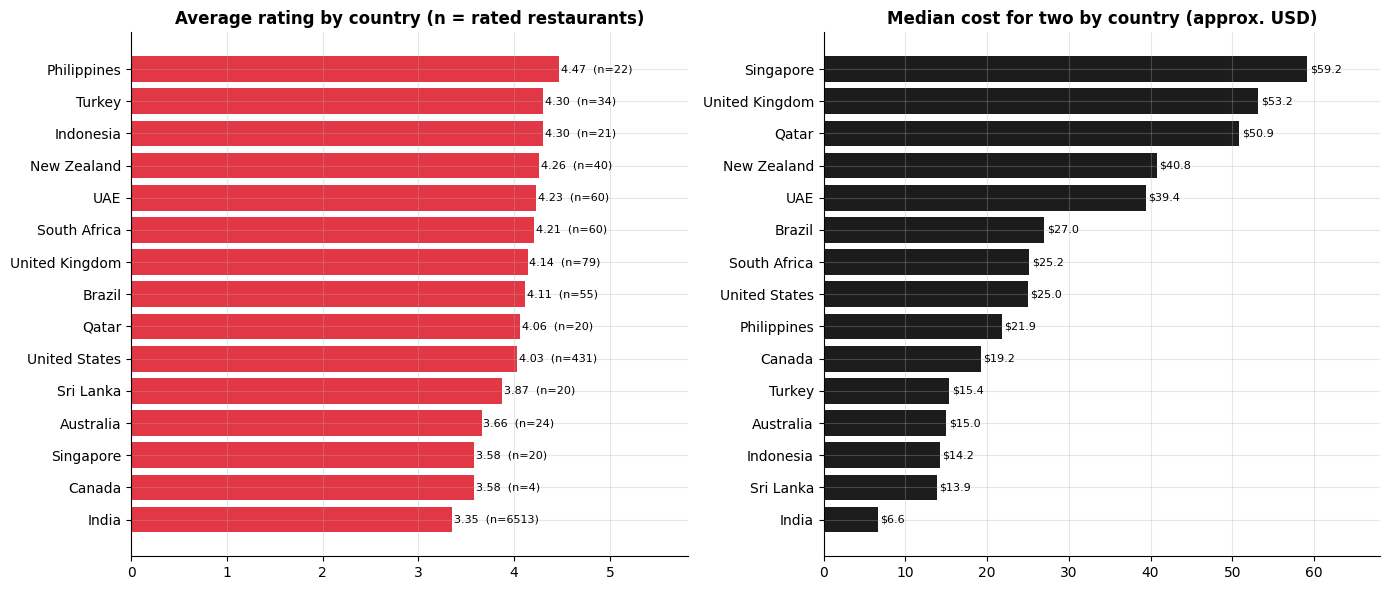

,restaurants,rated,avg_rating,median_cost_usd
Country,,,,
Philippines,22,22,4.47,21.85
Indonesia,21,21,4.30,14.20
Turkey,34,34,4.30,15.40
New Zealand,40,40,4.26,40.80
UAE,60,60,4.23,39.44
South Africa,60,60,4.21,25.16
United Kingdom,80,79,4.14,53.20
Brazil,60,55,4.11,27.00
Qatar,20,20,4.06,50.88


In [25]:
country_stats = (
    df.groupby("Country")
      .agg(restaurants=("Restaurant ID", "count"),
           rated=("Is Rated", "sum"),
           avg_rating=("Aggregate rating", "mean"),
           median_cost_usd=("Cost for two (USD)", "median"))
      .round(2)
      .sort_values("avg_rating", ascending=False)
)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
r = country_stats["avg_rating"].sort_values()
ax[0].barh(r.index, r.values, color=RED)
for i, (name, v) in enumerate(r.items()):
    ax[0].text(v + 0.02, i, f"{v:.2f}  (n={int(country_stats.loc[name, 'rated'])})", va="center", fontsize=8)
ax[0].set_xlim(0, r.max() * 1.3)
ax[0].set_title("Average rating by country (n = rated restaurants)")

c = country_stats["median_cost_usd"].sort_values()
ax[1].barh(c.index, c.values, color=DARK)
for i, v in enumerate(c.values):
    ax[1].text(v + 0.3, i, f"${v:.1f}", va="center", fontsize=8)
ax[1].set_xlim(0, c.max() * 1.15)
ax[1].set_title("Median cost for two by country (approx. USD)")
save_fig("13_country_rating_and_cost")

country_stats

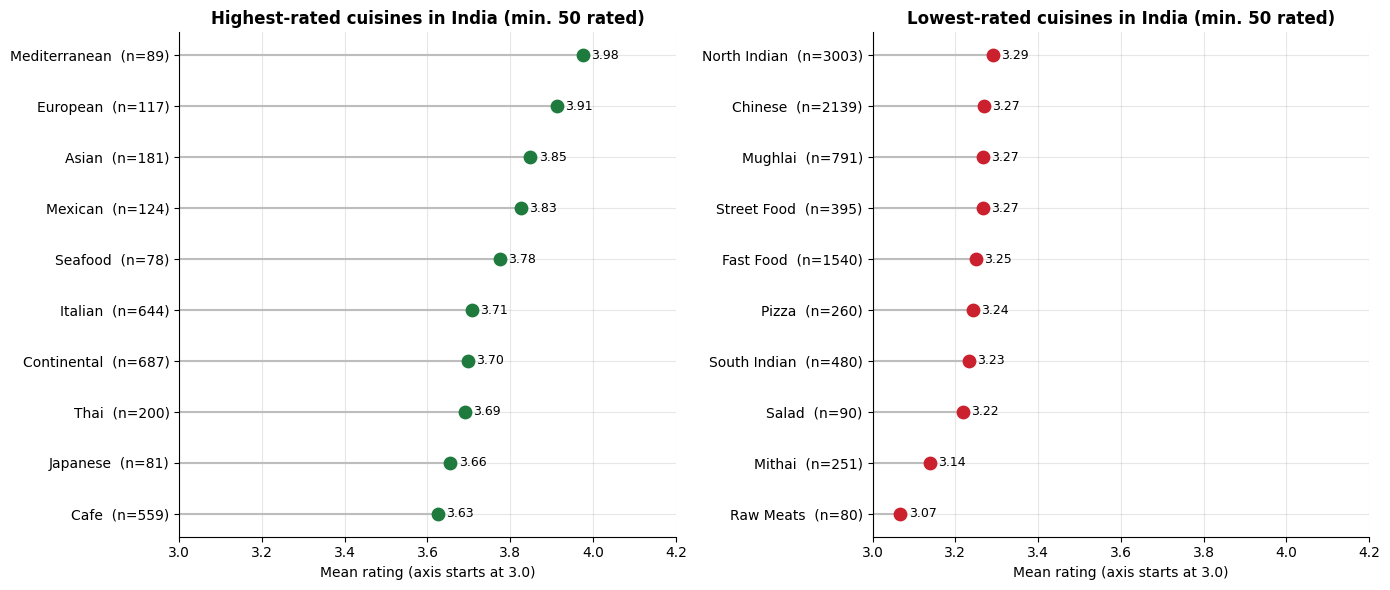

In [26]:
# India only: cuisine ratings are otherwise skewed by the country mix (non-India places rate higher)
rated_cuisine = cuisine_df[cuisine_df["Is Rated"] & (cuisine_df["Country"] == "India")]
cstats = rated_cuisine.groupby("Cuisine")["Aggregate rating"].agg(["count", "mean"])
cstats = cstats[cstats["count"] >= 50].sort_values("mean")

fig, ax = plt.subplots(1, 2, figsize=(14, 6), sharex=True)
best, worst = cstats.tail(10), cstats.head(10)
panels = [(ax[0], best, "#1F7A3E", "Highest-rated cuisines in India (min. 50 rated)"),
          (ax[1], worst, "#CB202D", "Lowest-rated cuisines in India (min. 50 rated)")]
for a_, d, color, title in panels:
    pos = np.arange(len(d))
    a_.hlines(pos, 3.0, d["mean"], color=GREY, lw=1.5)
    a_.scatter(d["mean"], pos, s=80, color=color, zorder=3)
    a_.set_yticks(pos)
    a_.set_yticklabels([f"{c}  (n={int(n)})" for c, n in zip(d.index, d["count"])])
    for y, v in zip(pos, d["mean"]):
        a_.text(v + 0.02, y, f"{v:.2f}", va="center", fontsize=9)
    a_.set_xlim(3.0, 4.2)
    a_.set_xlabel("Mean rating (axis starts at 3.0)")
    a_.set_title(title)
save_fig("14_cuisine_ratings")

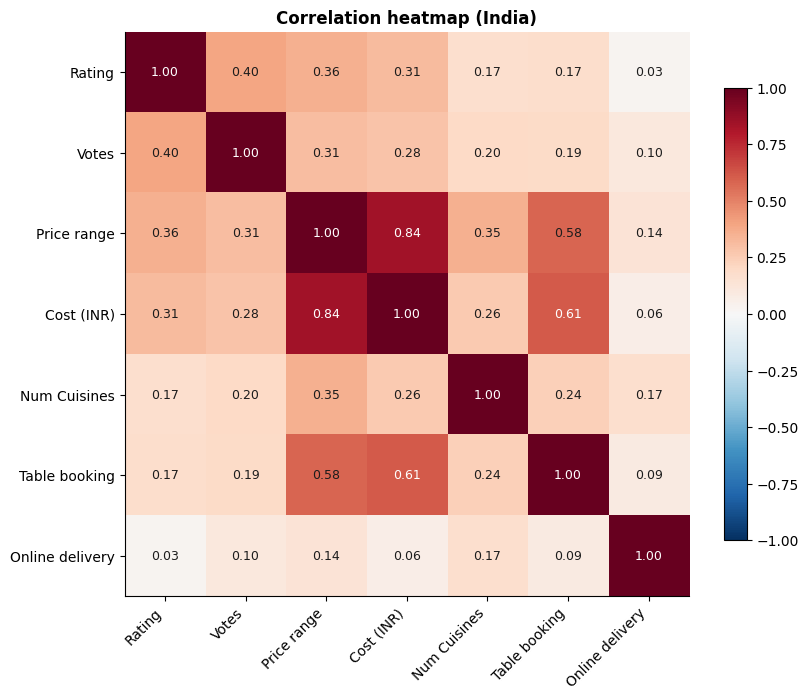

,Rating,Votes,Price range,Cost (INR),Num Cuisines,Table booking,Online delivery
Rating,1.00,0.40,0.36,0.31,0.17,0.17,0.03
Votes,0.40,1.00,0.31,0.28,0.20,0.19,0.10
Price range,0.36,0.31,1.00,0.84,0.35,0.58,0.14
Cost (INR),0.31,0.28,0.84,1.00,0.26,0.61,0.06
Num Cuisines,0.17,0.20,0.35,0.26,1.00,0.24,0.17
Table booking,0.17,0.19,0.58,0.61,0.24,1.00,0.09
Online delivery,0.03,0.10,0.14,0.06,0.17,0.09,1.00


In [27]:
# Correlation heatmap - India only (91% of the data, one currency, so real cost is comparable)
ind = india.assign(
    **{"Table booking": (india["Has Table booking"] == "Yes").astype(int),
       "Online delivery": (india["Has Online delivery"] == "Yes").astype(int)}
).rename(columns={"Average Cost for two": "Cost (INR)", "Aggregate rating": "Rating"})

cols = ["Rating", "Votes", "Price range", "Cost (INR)", "Num Cuisines", "Table booking", "Online delivery"]
corr = ind[cols].corr()

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr.values[i, j]) > 0.6 else DARK, fontsize=9)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation heatmap (India)")
save_fig("15_correlation_heatmap")

corr.round(2)

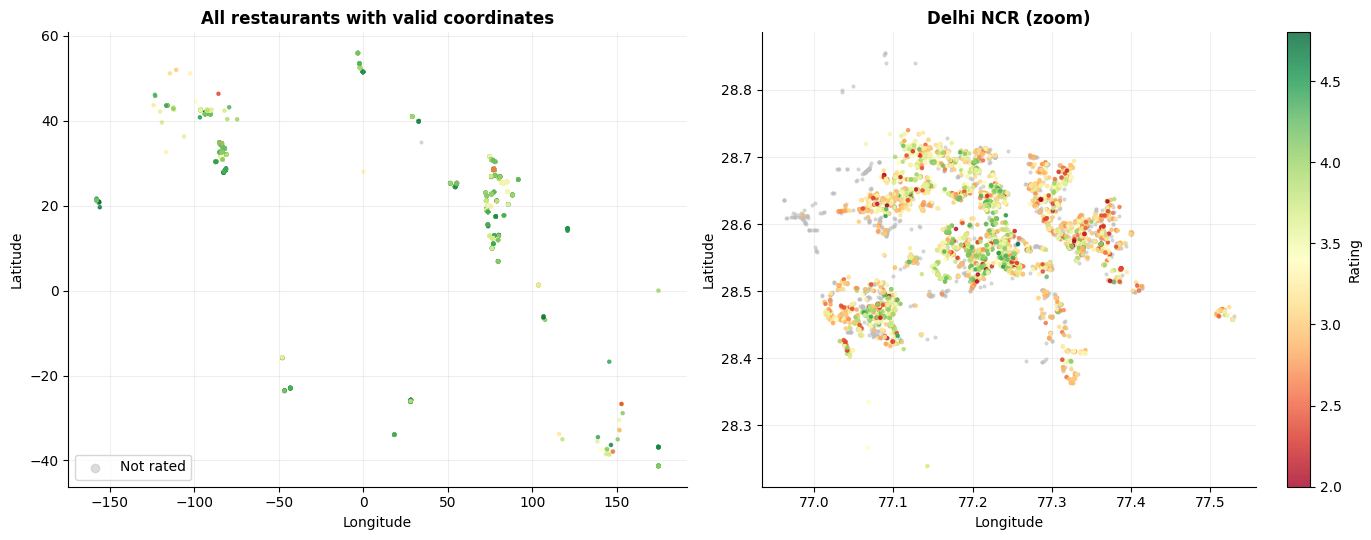

In [28]:
geo = df.dropna(subset=["Longitude", "Latitude"])
ncr = geo[geo["City"].isin(["New Delhi", "Gurgaon", "Noida", "Faridabad", "Ghaziabad"])]
ncr = ncr[(ncr["Longitude"].between(76.8, 77.7)) & (ncr["Latitude"].between(28.2, 29.0))]

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, data, title in zip(ax, [geo, ncr], ["All restaurants with valid coordinates", "Delhi NCR (zoom)"]):
    un = data[~data["Is Rated"]]
    ra = data[data["Is Rated"]]
    a.scatter(un["Longitude"], un["Latitude"], s=4, color=GREY, alpha=0.5, label="Not rated")
    sc = a.scatter(ra["Longitude"], ra["Latitude"], s=5, c=ra["Aggregate rating"], cmap="RdYlGn", vmin=2, vmax=4.8, alpha=0.8)
    a.set_xlabel("Longitude")
    a.set_ylabel("Latitude")
    a.set_title(title)
    a.grid(alpha=0.2)
fig.colorbar(sc, ax=ax[1], label="Rating")
ax[0].legend(loc="lower left", markerscale=3)
save_fig("16_geographic_scatter")

## 6. Key insights

In [29]:
print(f"Total restaurants          : {len(df):,}")
print(f"Countries / cities         : {df['Country'].nunique()} / {df['City'].nunique()}")
print(f"Share located in India     : {len(india) / len(df):.1%}")
print(f"Unrated restaurants        : {(~df['Is Rated']).sum():,} ({(~df['Is Rated']).mean():.1%})")
print(f"Mean / median rating       : {rated['Aggregate rating'].mean():.2f} / {rated['Aggregate rating'].median():.2f}")
print(f"Table booking available    : {(df['Has Table booking'] == 'Yes').mean():.1%}")
print(f"Online delivery available  : {(df['Has Online delivery'] == 'Yes').mean():.1%}")
print(f"Most common cuisine        : {cuisine_counts.index[0]} ({cuisine_counts.iloc[0]:,} restaurants)")
top_voted = df.loc[df["Votes"].idxmax()]
print(f"Most-voted restaurant      : {top_voted['Restaurant Name']}, {top_voted['City']} ({top_voted['Votes']:,} votes, rating {top_voted['Aggregate rating']})")

Total restaurants          : 9,551
Countries / cities         : 15 / 141
Share located in India     : 90.6%
Unrated restaurants        : 2,148 (22.5%)
Mean / median rating       : 3.44 / 3.40
Table booking available    : 12.1%
Online delivery available  : 25.7%
Most common cuisine        : North Indian (3,960 restaurants)
Most-voted restaurant      : Toit, Bangalore (10,934 votes, rating 4.8)


**Coverage and data caveats**
- **The dataset is India-centric:** 90.6% of restaurants are in India, and 83.2% are in Delhi NCR alone. The other 14 countries have only 4–434 restaurants each, so global comparisons are indicative, not representative.
- **22.5% of restaurants (2,148) have no rating.** 2,139 of them are in India (24.7% of Indian listings vs ~1% elsewhere), and they skew cheap: 38% of price-range-1 restaurants are unrated vs ~2% in price ranges 3–4.

**Ratings and popularity**
- Among rated restaurants the mean is **3.44** (median 3.40). Half are just "Average"; only **~4%** reach "Excellent" (4.5+).
- **Pricier means better rated:** mean rating climbs 3.24 → 3.38 → 3.78 → 3.89 from price range 1 to 4.
- **Votes are extremely skewed:** median 31, mean 157, and a third of restaurants have ≤ 10 votes. The most-voted place is Toit, Bangalore (10,934 votes, 4.8 rating).
- **Better rated means more votes** (Spearman 0.68). Median votes: 20 (Average), 121 (Good), 271 (Very Good), 489 (Excellent), roughly 24× more for Excellent than Average. One oddity: "Poor" places (median 61) draw more votes than "Average" ones.

**Cuisines (India)**
- **North Indian** is the most common cuisine (3,960 restaurants, listed by 46% of Indian restaurants), yet it sits near the bottom on rating (3.29), together with Chinese, Fast Food and Street Food (3.25–3.27).
- Highest rated: **Mediterranean (3.98), European (3.91), Asian (3.85), Mexican (3.83)**. Lowest: **Raw Meats (3.07), Mithai (3.14), Salad (3.22)**. Sit-down / international cuisines rate higher than everyday staples and takeaway-style formats, which also tracks price range.

**Service options**
- **Online delivery exists only in India (28%) and UAE (47%)** in this data, so it can't be generalised. In India it has almost no relation to rating (3.37 vs 3.34, correlation 0.03) but delivering restaurants get more votes (median 83 vs 33).
- **Table booking looks like a rating boost (+0.24 in India) but it's a price effect.** Booking restaurants have an average price range of 3.0 vs 1.7. At the *same* price range they are rated equal (range 2: 3.36 vs 3.31) or **lower** (range 3: 3.59 vs 3.79; range 4: 3.62 vs 3.94). Table booking marks an upscale venue; it doesn't cause better ratings. (Higher expectations at upscale venues is a plausible reason, but not tested here.)

**Countries and cost**
- India has the lowest average rating (3.35) and by far the lowest median cost for two (~$6.6 vs ~$25 in the US, ~$53 in the UK, ~$59 in Singapore; approximate FX). The rating gap is **not like-for-like**: the non-India samples are small, ~99% rated, and look curated.

**What moves together (India)**
- Rating correlates moderately with votes (0.40), price range (0.36) and cost (0.31). Price range and cost are tightly linked (0.84), and table booking tracks cost (0.61). Online delivery is weakly related to everything (|r| ≤ 0.17).

**Limitations & next steps**
- Exchange rates are fixed approximations; 103 restaurant names and 89 addresses contain unrecoverable corrupted characters; there is no timestamp, so trends over time are impossible; all findings are correlations, not causes.
- Natural follow-ups: a model to predict rating from price, cuisine and locality; locality-level analysis inside Delhi NCR; handling the 2,139 unrated Indian restaurants separately (are they new, closed or simply low-traffic?).

## 7. Save the cleaned dataset

In [30]:
df.to_csv("data/zomato_cleaned.csv", index=False)

check = pd.read_csv("data/zomato_cleaned.csv")
print("Saved  : data/zomato_cleaned.csv")
print("Shape  :", check.shape)
print("Columns:", list(check.columns))

Saved  : data/zomato_cleaned.csv
Shape  : (9551, 25)
Columns: ['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes', 'Country', 'Currency Code', 'Is Rated', 'Cost for two (USD)', 'Num Cuisines', 'Primary Cuisine']
